# Experiment 3 — Stronger CNN Backbones on Colab

This notebook compares ImageNet-pretrained ResNet50 and ConvNeXt-Tiny under the same split,
preprocessing and checkpoint criterion. Run one model at a time if Colab runtime is limited.

## 1. Configuration

In [1]:
import json
import random
import shutil
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

IN_COLAB                    = 'google.colab' in sys.modules
RANDOM_STATE                = 42
BATCH_SIZE                  = 32
NUM_WORKERS                 = 2 if IN_COLAB else 8
EXPECTED_VALIDATION_ROWS    = 16_984

MODEL_NAMES                 = ['resnet50', 'convnext_tiny']  # Remove one entry to run only one model.
HEAD_EPOCHS                 = 1
LAST_BLOCK_EPOCHS           = 3
HEAD_LEARNING_RATE          = 1e-3
LAST_BLOCK_LEARNING_RATE    = 1e-4
WEIGHT_DECAY                = 1e-4

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    DRIVE_DIR               = Path('/content/drive/MyDrive/rakuten_colab')
    IMAGE_ZIP_PATH          = DRIVE_DIR / 'image_train.zip'
    MANIFEST_DRIVE_PATH     = DRIVE_DIR / 'image_split_clean.csv'
    OUTPUT_DIR              = DRIVE_DIR / 'outputs'

    LOCAL_DIR               = Path('/content/rakuten_experiment')
    LOCAL_IMAGE_DIR         = LOCAL_DIR / 'images'
    LOCAL_MANIFEST_PATH     = LOCAL_DIR / 'image_split_clean.csv'
else:
    PROJECT_ROOT            = Path.cwd().resolve()
    while PROJECT_ROOT.name in {'03_image_fineTuning', 'notebooks'}:
        PROJECT_ROOT = PROJECT_ROOT.parent

    LOCAL_IMAGE_DIR         = PROJECT_ROOT / 'data' / 'raw' / 'images' / 'image_train'
    LOCAL_MANIFEST_PATH     = PROJECT_ROOT / 'data' / 'processed' / 'image_split_clean.csv'
    OUTPUT_DIR              = PROJECT_ROOT / 'models' / 'outputs'

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('No GPU found. Make sure CUDA is available.')

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('Mode   :', 'Colab' if IN_COLAB else 'Local')
print('Device :', torch.cuda.get_device_name(0))
print('Outputs:', OUTPUT_DIR)

Mode   : Local
Device : NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
Outputs: /home/bquehl/Development/Rakuten2/Rakuten2/liora-capstone/models/outputs


## 2. Stage images and verify the shared split

In [2]:
if IN_COLAB:
    assert IMAGE_ZIP_PATH.exists(), f'Missing private image archive: {IMAGE_ZIP_PATH}'
    assert MANIFEST_DRIVE_PATH.exists(), f'Missing split manifest: {MANIFEST_DRIVE_PATH}'

    LOCAL_DIR.mkdir(parents=True, exist_ok=True)
    LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
    shutil.copy2(MANIFEST_DRIVE_PATH, LOCAL_MANIFEST_PATH)

    if not any(LOCAL_IMAGE_DIR.rglob('*.jpg')):
        local_zip_path = LOCAL_DIR / IMAGE_ZIP_PATH.name
        shutil.copy2(IMAGE_ZIP_PATH, local_zip_path)
        with zipfile.ZipFile(local_zip_path) as archive:
            archive.extractall(LOCAL_IMAGE_DIR)
        local_zip_path.unlink()
else:
    assert LOCAL_IMAGE_DIR.exists(), f'Missing image directory: {LOCAL_IMAGE_DIR}'
    assert LOCAL_MANIFEST_PATH.exists(), f'Missing split manifest: {LOCAL_MANIFEST_PATH}'

image_paths         = list(LOCAL_IMAGE_DIR.rglob('*.jpg'))
filename_to_path    = {path.name: path for path in image_paths}

if len(filename_to_path) != len(image_paths):
    raise ValueError('Duplicate image filenames were found inside the image directory.')

manifest            = pd.read_csv(LOCAL_MANIFEST_PATH)
required_columns    = {'row_id', 'imageid', 'productid', 'prdtypecode', 'split'}
assert required_columns.issubset(manifest.columns)
assert manifest['row_id'].is_unique
assert set(manifest['split']) == {'train', 'validation'}

# Validation must remain identical for image, text and fusion experiments.
validation_rows = int(manifest['split'].eq('validation').sum())
assert validation_rows == EXPECTED_VALIDATION_ROWS, (
    f'Validation contains {validation_rows:,} rows instead of {EXPECTED_VALIDATION_ROWS:,}.'
)

class_codes         = sorted(manifest['prdtypecode'].astype(int).unique().tolist())
assert len(class_codes) == 27
class_to_index      = {code: index for index, code in enumerate(class_codes)}
index_to_class      = {index: code for code, index in class_to_index.items()}
manifest['target']  = manifest['prdtypecode'].astype(int).map(class_to_index)

expected_names = [
    f'image_{int(row.imageid)}_product_{int(row.productid)}.jpg'
    for row in manifest.itertuples(index=False)
]
manifest['image_path']  = [filename_to_path.get(name) for name in expected_names]
missing_mask            = manifest['image_path'].isna()
if missing_mask.any():
    examples = [expected_names[i] for i in np.flatnonzero(missing_mask.to_numpy())[:5]]
    raise FileNotFoundError(f'{missing_mask.sum():,} images are missing. Examples: {examples}')

train_manifest      = manifest.loc[manifest['split'].eq('train')].reset_index(drop=True)
validation_manifest = manifest.loc[manifest['split'].eq('validation')].reset_index(drop=True)

display(pd.DataFrame({
    'rows': [len(train_manifest), len(validation_manifest)],
    'classes': [train_manifest['target'].nunique(), validation_manifest['target'].nunique()],
}, index=['train', 'validation']))

,rows,classes
train,62312,27
validation,16984,27


## 3. Use identical data transformations for a fair comparison

In [3]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.80, 1.00)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
validation_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class RakutenImageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['image_path']) as image:
            image_tensor = self.transform(image.convert('RGB'))
        return image_tensor, int(row['target']), int(row['row_id'])


def make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE):
    train_dataset       = RakutenImageDataset(train_manifest, train_transform)
    validation_dataset  = RakutenImageDataset(validation_manifest, validation_transform)
    options = {
        'batch_size'        : batch_size,
        'num_workers'       : NUM_WORKERS,
        'pin_memory'        : True,
        'persistent_workers': NUM_WORKERS > 0,
    }
    generator           = torch.Generator().manual_seed(RANDOM_STATE)
    train_loader        = DataLoader(train_dataset, shuffle=True, generator=generator, **options)
    validation_loader   = DataLoader( validation_dataset, shuffle=False, **options)
    return train_loader, validation_loader


@torch.no_grad()
def evaluate(model, loader, criterion, return_probabilities=False):
    model.eval()
    loss_total  = 0.0
    row_count   = 0
    targets_all, predictions_all, row_ids_all, probabilities_all = [], [], [], []

    for images, targets, row_ids in tqdm(loader, desc='Validation'):
        images      = images.to(device, non_blocking=True)
        targets     = targets.to(device, non_blocking=True)

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits  = model(images)
            loss    = criterion(logits, targets)

        probabilities    = torch.softmax(logits.float(), dim=1)
        predictions      = probabilities.argmax(dim=1)
        batch_size       = targets.size(0)
        loss_total      += loss.item() * batch_size
        row_count       += batch_size
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(predictions.cpu().tolist())
        row_ids_all.extend(row_ids.tolist())
        if return_probabilities:
            probabilities_all.append(probabilities.cpu().numpy())

    y_true = np.asarray(targets_all)
    y_pred = np.asarray(predictions_all)
    result = {
        'validation_loss'   : loss_total / row_count,
        'accuracy'          : accuracy_score(y_true, y_pred),
        'weighted_f1'       : f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'macro_f1'          : f1_score(y_true, y_pred, average='macro', zero_division=0),
        'targets'           : y_true,
        'predictions'       : y_pred,
        'row_ids'           : np.asarray(row_ids_all),
    }
    if return_probabilities:
        result['probabilities'] = np.concatenate(probabilities_all)
    return result


def save_evaluation(result, prefix):
    metrics = {
        key: float(result[key])
        for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']
    }
    prediction_frame = pd.DataFrame({
        'row_id'                : result['row_ids'],
        'true_prdtypecode'      : [index_to_class[int(x)] for x in result['targets']],
        'predicted_prdtypecode' : [index_to_class[int(x)] for x in result['predictions']],
    })
    for class_index, class_code in enumerate(class_codes):
        prediction_frame[f'prob_{class_code}'] = result['probabilities'][:, class_index]

    precision, recall, per_class_f1, support = precision_recall_fscore_support(
        result['targets'], result['predictions'], labels=np.arange(len(class_codes)),
        zero_division=0,
    )
    per_class = pd.DataFrame({
        'prdtypecode'   : class_codes,
        'precision'     : precision,
        'recall'        : recall,
        'f1'            : per_class_f1,
        'support'       : support,
    })

    prediction_frame.to_csv(OUTPUT_DIR / f'{prefix}_validation_predictions.csv', index=False)
    per_class.to_csv(OUTPUT_DIR / f'{prefix}_validation_per_class.csv', index=False)
    (OUTPUT_DIR / f'{prefix}_validation_metrics.json').write_text(json.dumps(metrics, indent=2))

    assert len(prediction_frame) == EXPECTED_VALIDATION_ROWS
    assert prediction_frame['row_id'].is_unique

    display(pd.DataFrame([metrics], index=[prefix]).style.format('{:.4f}'))
    display(per_class.sort_values('f1').style.format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1': '{:.3f}'}))

    return prediction_frame, per_class


train_loader, validation_loader = make_loaders(train_transform, validation_transform, batch_size=BATCH_SIZE)

## 4. Build each model and expose its final block

In [4]:
from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    ResNet50_Weights,
    convnext_tiny,
    resnet50,
)

def build_model(model_name):
    if model_name == 'resnet50':
        model = resnet50(weights=ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, len(class_codes))
        return model, model.fc, model.layer4
    if model_name == 'convnext_tiny':
        model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.DEFAULT)
        model.classifier[2] = nn.Linear(model.classifier[2].in_features, len(class_codes))
        return model, model.classifier, model.features[-1]
    raise ValueError(f'Unsupported model: {model_name}')


def train_one_epoch(model, loader, optimizer, criterion, train_mode_callback=None):
    model.train()
    if train_mode_callback is not None:
        train_mode_callback(model)
    scaler = torch.amp.GradScaler('cuda')
    loss_total = 0.0
    row_count = 0

    for images, targets, _ in tqdm(loader, desc='Training'):
        images      = images.to(device, non_blocking=True)
        targets     = targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            logits  = model(images)
            loss    = criterion(logits, targets)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        batch_size  = targets.size(0)
        loss_total += loss.item() * batch_size
        row_count  += batch_size

    return loss_total / row_count

## 5. Train the head, then the final feature block

In [5]:
comparison = []
histories  = {}

for model_name in MODEL_NAMES:
    print(f'\n===== {model_name} =====')
    model, head, last_block = build_model(model_name)
    model           = model.to(device)
    criterion       = nn.CrossEntropyLoss()
    best_macro_f1   = -np.inf
    checkpoint_path = OUTPUT_DIR / f'03_5_{model_name}_best.pt'
    history         = []
    global_epoch    = 0

    for phase_name, epochs in [('head', HEAD_EPOCHS), ('last_block', LAST_BLOCK_EPOCHS)]:
        for parameter in model.parameters():
            parameter.requires_grad = False
        for parameter in head.parameters():
            parameter.requires_grad = True
        if phase_name == 'last_block':
            for parameter in last_block.parameters():
                parameter.requires_grad = True

        trainable       = [parameter for parameter in model.parameters() if parameter.requires_grad]
        learning_rate   = (HEAD_LEARNING_RATE if phase_name == 'head' else LAST_BLOCK_LEARNING_RATE)
        optimizer = torch.optim.AdamW(trainable, lr=learning_rate, weight_decay=WEIGHT_DECAY)

        def mode_callback(network):
            network.eval()
            head.train()
            if phase_name == 'last_block':
                last_block.train()

        for phase_epoch in range(1, epochs + 1):
            global_epoch += 1
            train_loss = train_one_epoch(
                model, train_loader, optimizer, criterion, mode_callback
            )
            result = evaluate(model, validation_loader, criterion)
            row = {
                'model'         : model_name,
                'global_epoch'  : global_epoch,
                'phase'         : phase_name,
                'phase_epoch'   : phase_epoch,
                'train_loss'    : train_loss,
                **{key: result[key] for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
            }
            history.append(row)
            pd.DataFrame(history).to_csv(OUTPUT_DIR / f'03_5_{model_name}_history.csv', index=False)
            display(pd.DataFrame([row]).style.format({
                'train_loss'        : '{:.4f}',
                'validation_loss'   : '{:.4f}',
                'accuracy'          : '{:.4f}',
                'weighted_f1'       : '{:.4f}',
                'macro_f1'          : '{:.4f}',
            }))

            if result['macro_f1'] > best_macro_f1:
                best_macro_f1 = result['macro_f1']
                torch.save({
                    'model_name'        : model_name,
                    'model_state_dict'  : {key: value.detach().cpu() for key, value in model.state_dict().items()},
                    'class_to_index'    : class_to_index,
                    'validation_metrics': {key: float(result[key]) for key in ['validation_loss', 'accuracy', 'weighted_f1', 'macro_f1']},
                }, checkpoint_path)

    histories[model_name]       = history
    best                        = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(best['model_state_dict'])
    final_result                = evaluate(model, validation_loader, criterion, return_probabilities=True)
    prediction_frame, per_class = save_evaluation(final_result, f'03_5_{model_name}')
    comparison.append({'model': model_name, **best['validation_metrics']})
    del model
    torch.cuda.empty_cache()

comparison_frame = pd.DataFrame(comparison).sort_values('macro_f1', ascending=False)
display(comparison_frame.style.format(precision=4))
comparison_frame.to_csv(OUTPUT_DIR / '03_5_cnn_backbone_comparison.csv', index=False)


===== resnet50 =====


Validation: 100%|██████████| 531/531 [00:18<00:00, 28.45it/s]


,model,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,resnet50,1,head,1,1.5646,1.3831,0.5901,0.5838,0.5385


Validation: 100%|██████████| 531/531 [00:18<00:00, 28.55it/s]


,model,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,resnet50,2,last_block,1,1.1870,1.1311,0.6583,0.6548,0.6228


Validation: 100%|██████████| 531/531 [00:18<00:00, 28.62it/s]


... (15 outputs left out)

Validation: 100%|██████████| 531/531 [00:22<00:00, 23.99it/s]


,validation_loss,accuracy,weighted_f1,macro_f1
convnext_tiny,1.1671,0.6766,0.6739,0.6458


,prdtypecode,precision,recall,f1,support
8,1281,0.411,0.350,0.378,414
24,2585,0.480,0.439,0.459,499
7,1280,0.479,0.451,0.464,974
22,2582,0.504,0.459,0.481,518
6,1180,0.606,0.431,0.504,153
11,1302,0.506,0.506,0.506,498
17,2220,0.580,0.503,0.539,165
0,10,0.584,0.549,0.566,623
16,2060,0.558,0.576,0.567,999
2,50,0.608,0.536,0.570,336


,model,validation_loss,accuracy,weighted_f1,macro_f1
1,convnext_tiny,1.1671,0.6766,0.6739,0.6458
0,resnet50,1.1799,0.6723,0.6707,0.6415


## 6. Training curves

Use validation loss and macro F1 to assess generalisation for each backbone. A falling training loss combined with a rising validation loss indicates overfitting.

,model,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,resnet50,1,head,1,1.5646,1.3831,0.5901,0.5838,0.5385
1,resnet50,2,last_block,1,1.1870,1.1311,0.6583,0.6548,0.6228
2,resnet50,3,last_block,2,0.8600,1.1223,0.6705,0.6692,0.6372
3,resnet50,4,last_block,3,0.6110,1.1799,0.6723,0.6707,0.6415


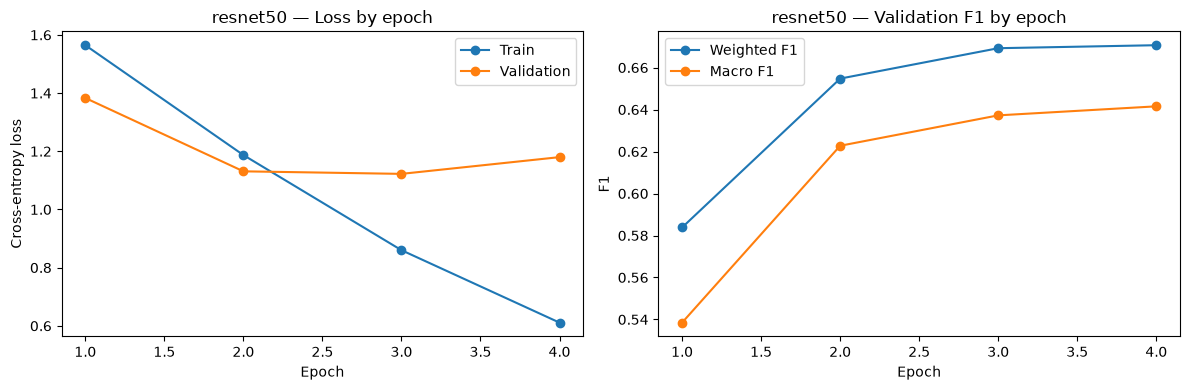

,model,global_epoch,phase,phase_epoch,train_loss,validation_loss,accuracy,weighted_f1,macro_f1
0,convnext_tiny,1,head,1,1.5254,1.3740,0.5894,0.5816,0.5427
1,convnext_tiny,2,last_block,1,1.2034,1.1308,0.6572,0.6545,0.6211
2,convnext_tiny,3,last_block,2,0.8486,1.1198,0.6686,0.6657,0.6327
3,convnext_tiny,4,last_block,3,0.5391,1.1671,0.6766,0.6739,0.6458


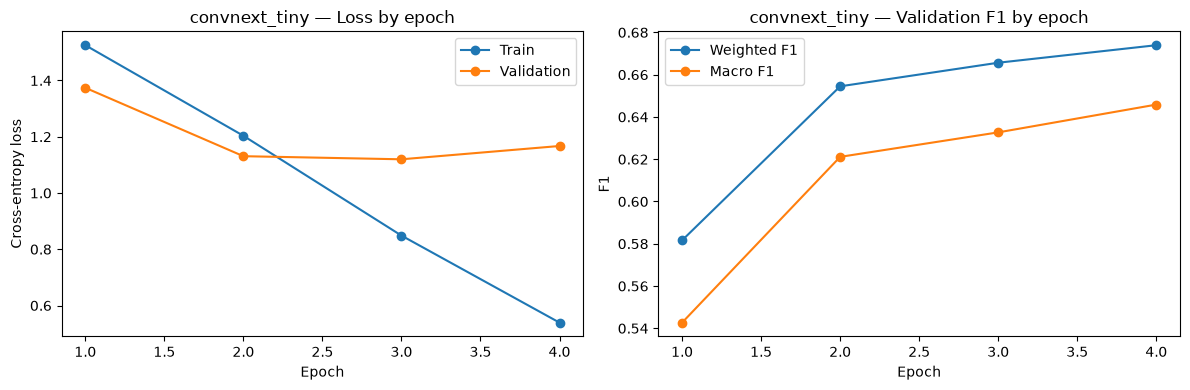

In [6]:
for model_name in MODEL_NAMES:
    history_frame = pd.DataFrame(histories[model_name])
    display(history_frame.style.format({
        'train_loss'        : '{:.4f}',
        'validation_loss'   : '{:.4f}',
        'accuracy'          : '{:.4f}',
        'weighted_f1'       : '{:.4f}',
        'macro_f1'          : '{:.4f}',
    }))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history_frame['global_epoch'], history_frame['train_loss'], marker='o', label='Train')
    axes[0].plot(history_frame['global_epoch'], history_frame['validation_loss'], marker='o', label='Validation')
    axes[0].set(title=f'{model_name} — Loss by epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
    axes[0].legend()

    axes[1].plot(history_frame['global_epoch'], history_frame['weighted_f1'], marker='o', label='Weighted F1')
    axes[1].plot(history_frame['global_epoch'], history_frame['macro_f1'], marker='o', label='Macro F1')
    axes[1].set(title=f'{model_name} — Validation F1 by epoch', xlabel='Epoch', ylabel='F1')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## Interpretation

Select the backbone using macro F1 first and weighted F1 second. Because both candidates are
evaluated on the same 16984 rows, the scores and per-class changes are directly comparable.